# Probability

## Challenge 1
There is a box with 10 white balls, 12 red balls and 8 black balls. Calculate the probability of:
* Taking a white ball out.
* Taking a white ball on first extraction and a black ball out on second extraction without replacing the first one.
* Taking a white ball on first extraction and a black ball out on second extraction replacing the first one.
* Taking 3 balls and them being all different colours.

In [1]:
from math import factorial

# 1 --- Overall probability
p_white: float = 10/30
print(f"Probability of white draw: {p_white:.1%}")

# 2 --- Sequential probability
p_white_then_black: float = 10/30 * 8/29
print(f"Probability of white then black draw (without replacement): {p_white_then_black:.1%}")

# 3 --- Independent probability
p_white_and_black: float = 10/30 * 8/30
print(f"Probability of white then black draw (with replacement): {p_white_and_black:.1%}")

# 4 Sequential probability multiplied by n of possible permutations
n_permutations: int = factorial(3)
p_white_red_black: float = ((10/30) * (12/29) * (8/28)) * n_permutations 

print(f"Probability of white, red and black simultaneously: {p_white_red_black:.1%}")

Probability of white draw: 33.3%
Probability of white then black draw (without replacement): 9.2%
Probability of white then black draw (with replacement): 8.9%
Probability of white, red and black simultaneously: 23.6%


## Challenge 2

You want to go on picnic on Saturday. You hate rain, and would know to plan your weekend. To help you make a decision, you gather the following data about rainy days:

* 40% of all days are cloudy.
* About 50% of cloudy days are rainy. 
* About 20% of non-cloudy days are rainy.

What is the chance of rain during next Saturday?

In [2]:
# Probabilities of cloudy day
p_clouds: float = 0.4
p_no_clouds: float = 0.6

# Likelihood of rain given cloudy day
p_rain_given_clouds: float = 0.5
p_rain_given_no_clouds: float = 0.2

# Total probability of rain
p_rain: float = (
    p_rain_given_clouds * p_clouds +
    p_rain_given_no_clouds * p_no_clouds
)

print(f"Chance of rain: {p_rain:.1%}")

Chance of rain: 32.0%


## Challenge 3

A and B are events of a probability such that $P(A) = 0.3$, $P(B) = 0.6$ and $P(A \cap B) = 0.1$

Which of the following statements are true?  
**HINT: draw a big Venn Diagram by your side**  
* $P(\overline{A}) = 0.7$
* $P(A \cup B) = 0.6$
* $P(A \cap \overline{B}) = 0.2$
* $P(A \cup \overline{A}) = 1$  
* $P(A \cap (B \cup \overline{B})) = 0.4$
* $P(\overline{A} \cap \overline{B}) = 0.3$
* $P(\overline{A \cap B}) = 0.9$

In [3]:
# 1
True

# 2
False

# 3
True

# 4
True

# 5
False

# 6
False

# 7
True

True

## Challenge 4

 * If someone flies to China, the probability of getting Covid is 1%  
 * If someone flies to Italy, the probability of getting Covid is 20%  

I roll 1 dice with numbers 1, 2, 3, 4, 5, 6:  
 * If 1: I fly to Italy
 * If not 1: I fly to China

During my trip, I got Covid. What is the probability that I flew to China?

In [4]:
# Probabilities of China and Italy
p_china: float = 5/6
p_italy: float = 1/6

# Likelihood of covid given China and Italy
p_covid_given_china: float = 0.01
p_covid_given_italy: float = 0.2

# Total possibility of Covid
p_covid: float = (
    p_covid_given_china * p_china +
    p_covid_given_italy * p_italy
)

# Bayes' theorem P(China | Covid)
p_china_given_covid: float = (p_china * p_covid_given_china) / p_covid

print(f"Chance of covid: {p_covid:.1%}")
print(f"Chance of covid from China: {p_china_given_covid:.1%}")
print(f"Chance of covid from Italy: {1 - p_china_given_covid:.1%}")

Chance of covid: 4.2%
Chance of covid from China: 20.0%
Chance of covid from Italy: 80.0%


## BONUS

You roll 2 dice. What is the probability that the sum of the numbers is 7? And 8? And 9? Then simulate 10000 times and draw a countplot.

In [5]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from random import randint

In [6]:
p_7: float = (6/6) * (1/6)
print(f"Chance of sum = 7: {p_7:.1%}")

p_8: float = (5/6) * (1/6)
print(f"Chance of sum = 8: {p_8:.1%}")

p_9: float = (4/6) * (1/6)
print(f"Chance of sum = 9: {p_9:.1%}")

Chance of sum = 7: 16.7%
Chance of sum = 8: 13.9%
Chance of sum = 9: 11.1%


In [7]:
df: pd.DataFrame = pd.DataFrame(
    data=[
        {"Roll_1": randint(1, 6), "Roll_2": randint(1, 6)}
        for _ in range(10000)
    ]
)
df["Sum"] = df.Roll_1 + df.Roll_2

df.head()

,Roll_1,Roll_2,Sum
0,2,4,6
1,2,1,3
2,5,6,11
3,3,3,6
4,5,5,10


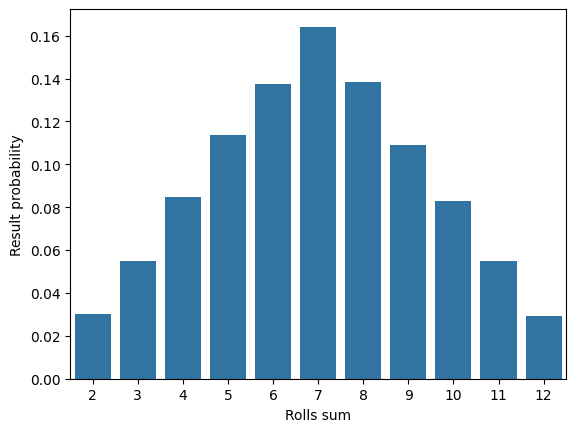

In [8]:
sns.countplot(
    data=df,
    x="Sum",
    stat="probability"
)

plt.xlabel("Rolls sum")
plt.ylabel("Result probability")
plt.show()

The resulting distribution of the countplot proves our estimates. ~0.16 result = 7 is in fact ~16.7% (and so on for the other results.)